# Member 3 Exploratory Data Analysis

**Author:** YANG Qitian (24128112D)  
**Team:** DataVinci, DSAI4205  
**Milestone:** EDA contribution for 4 November 2026

This notebook generates all six required EDA figures, the underlying CSV tables, a source-hash manifest and an English chapter draft. It uses the supplied raw and clean_v2 snapshots. No classifier is trained and no data cleaning rules are changed.

**Run:** keep this notebook beside `input_data` and use Restart Kernel and Run All. Inside the team repository it automatically prefers the repository data. Inputs, class coding, measurement definitions and limits are documented below. The attached notebook contains executed outputs.

Full-snapshot plots are descriptive course EDA; all later modelling and learned transformations must use the agreed development/test protocol. No test performance is measured here.

## Setup and configuration


In [1]:
from pathlib import Path
from collections import Counter
import base64
import hashlib
import html
import json
import platform
import re
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Usually no edit is needed. Set this to the extracted team repository if desired.
PROJECT_ROOT_OVERRIDE = None
HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
def locate_inputs():
    candidates = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else []
    for parent in [HERE, *HERE.parents]:
        candidates += [parent, parent / 'PolyU_DSAI4205_Group_Project-main']
    for parent in candidates:
        if (parent / 'data/clean_v2/clean_v2.csv').exists():
            return {'raw': parent / 'data/raw/stock_market_crash_2022.csv',
                    'clean': parent / 'data/clean_v2/clean_v2.csv',
                    'all': parent / 'data/clean_v2/clean_v2_all.csv'}
    if (HERE / 'input_data/clean_v2.csv').exists():
        return {'raw': HERE / 'input_data/raw.csv', 'clean': HERE / 'input_data/clean_v2.csv',
                'all': HERE / 'input_data/clean_v2_all.csv'}
    raise FileNotFoundError('Put this file in the delivery folder or team repository, or set PROJECT_ROOT_OVERRIDE.')

INPUTS = locate_inputs()
OUTPUT = HERE
FIGURES = OUTPUT / 'figures'
TABLES = OUTPUT / 'tables'
for folder in [FIGURES, TABLES]: folder.mkdir(parents=True, exist_ok=True)
CLASSES = ['Neutral', 'Positive', 'Negative']
COLORS = {'Neutral': '#64748b', 'Positive': '#008b76', 'Negative': '#cb573f'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13,
                     'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#ffffff', 'axes.facecolor': '#ffffff', 'savefig.facecolor': '#ffffff',
                     'svg.fonttype': 'none'})
def table(df, name):
    df.to_csv(TABLES / (name + '.csv'), index=False, encoding='utf-8-sig')
    return df
def finish(fig, name, title, subtitle, note):
    fig.suptitle(title, x=.06, y=.98, ha='left', fontsize=18, fontweight='bold', color='#172b3a')
    fig.text(.06, .918, subtitle, ha='left', fontsize=11, color='#475569')
    fig.text(.06, .027, note, ha='left', va='bottom', fontsize=9, color='#475569', wrap=True)
    left = .23 if name == 'eda_03_hashtags' else (.17 if name == 'eda_05_market_sentiment' else .08)
    top = .80 if name in ['eda_05_market_sentiment','eda_06_feature_relationships'] else .83
    bottom = .22 if name == 'eda_06_feature_relationships' else .17
    fig.subplots_adjust(left=left, right=.96, top=top, bottom=bottom, wspace=.3)
    fig.savefig(FIGURES / (name + '.png'), dpi=240)
    fig.savefig(FIGURES / (name + '.svg'))
    plt.close(fig)
    return name + '.png'



## Load and independently validate the supplied snapshot


In [2]:
raw = pd.read_csv(INPUTS['raw'])
clean = pd.read_csv(INPUTS['clean'])
all_rows = pd.read_csv(INPUTS['all'])
assert set(raw.columns) == {'text', 'text_sentiment'}
assert clean['id'].is_unique and all_rows['id'].is_unique
assert clean['label'].isin([0, 1, 2]).all()
assert clean['label_name'].equals(clean['label'].map(dict(enumerate(CLASSES))))
assert set(clean['id']) == set(all_rows.loc[all_rows['keep'].eq(1), 'id'])
assert all_rows.sort_values('id')['text_raw'].reset_index(drop=True).equals(raw['text'])
assert clean['text_raw'].reset_index(drop=True).equals(raw.loc[clean['id'], 'text'].reset_index(drop=True))
for col in ['text_clean','text_norm']:
    assert clean[col].fillna('').str.strip().ne('').all()
assert clean['char_len'].eq(clean['text_clean'].str.len()).all()
assert clean['word_len'].eq(clean['text_clean'].str.split().str.len()).all()
raw['label_name'] = raw['text_sentiment'].map(dict(enumerate(CLASSES)))
raw['char_len'] = raw['text'].str.len()
raw['word_len'] = raw['text'].str.split().str.len()
raw_missing = (raw['text'].isna() | raw['text'].fillna('').str.strip().eq('') | raw['text_sentiment'].isna()).sum()
raw_invalid = (~raw['text_sentiment'].isin([0,1,2])).sum()
group_sizes = clean.groupby('group_id').size()
retained = len(clean)
removed = len(raw)-retained
quality = table(pd.DataFrame([
    ['Unit of analysis','One tweet','One tweet','Counts describe records, not unique people'],
    ['Records',len(raw),retained,f'{removed} excluded ({removed/len(raw):.1%})'],
    ['Missing or blank text or missing label',int(raw_missing),0,'Logical OR across required fields'],
    ['Invalid sentiment labels',int(raw_invalid),0,'Valid codes are 0, 1, 2'],
    ['Exact duplicate extra rows',int(raw.duplicated('text').sum()),int(clean.duplicated('text_raw').sum()),'Copies beyond the first occurrence'],
    ['Median characters',float(raw['char_len'].median()),float(clean['char_len'].median()),'Raw text versus text_clean; cleaning also changes the retained population'],
    ['Median whitespace tokens',float(raw['word_len'].median()),float(clean['word_len'].median()),'Whitespace tokens, not transformer tokens'],
    ['Unique related-text groups','Not assigned',int(clean['group_id'].nunique()),'Groups are supplied by the cleaning pipeline'],
    ['Records in non-singleton groups','Not assigned',int(group_sizes[group_sizes.gt(1)].sum()),'Keep related records in the same split and fold'],
    ['Non-singleton groups','Not assigned',int(group_sizes.gt(1).sum()),'Near-duplicates remain grouped rather than all being deleted'],
    ['Records with lost-character flag','Not audited here',int(clean['emoji_lost'].sum()),'Pipeline flag; not a count of recoverable emoji']
], columns=['measure','raw','clean_v2','interpretation']), 'eda_data_quality')
removals = table(all_rows.loc[all_rows['keep'].eq(0)].groupby('drop_reason').size().rename('records').reset_index(), 'eda_removed_records')
assert int(removals['records'].sum()) == removed
stats_rows=[]
for name, data in [('Raw',raw),('Clean v2',clean)]:
    for lab in CLASSES:
        sub=data[data['label_name'].eq(lab)]
        stats_rows.append({'dataset':name,'sentiment':lab,'n':len(sub),'share':len(sub)/len(data),
          'char_median':sub['char_len'].median(),'char_q1':sub['char_len'].quantile(.25),
          'char_q3':sub['char_len'].quantile(.75),'word_median':sub['word_len'].median(),
          'char_min':sub['char_len'].min(),'char_max':sub['char_len'].max()})
length_stats=table(pd.DataFrame(stats_rows),'eda_length_by_class')
print('Loaded and validated:',len(raw),'raw;',len(clean),'retained;',removed,'removed')
print(quality.to_string(index=False))

# Data dictionary and supplementary audit tables are part of the EDA handoff.
definitions={
 'id':('identifier','Stable zero-based row ID in the raw CSV'),
 'group_id':('grouping only','Related tweets share a group; keep the group in one fold'),
 'label':('target','0 Neutral; 1 Positive; 2 Negative'),
 'label_name':('target display','Text form of label; not an input feature'),
 'text_raw':('audit','Original tweet text'),
 'text_clean':('text input','Repaired text preserving case and punctuation'),
 'text_norm':('text input','Team-normalized lemmatized text; stopwords removed with exceptions'),
 'hashtags':('EDA','Lowercase hashtag list separated by spaces'),
 'lang':('quality','Supplied language heuristic; not independent language verification'),
 'emoji_lost':('quality or candidate feature','Flag for lost source characters'),
 'char_len':('candidate feature','Number of characters in text_clean'),
 'word_len':('candidate feature','Number of whitespace tokens in text_clean'),
 'n_hashtags':('candidate feature','Hashtag count before hashtag normalization'),
 'n_mentions':('candidate feature','Mention count before anonymization'),
 'n_cashtags':('candidate feature','Cashtag count'),
 'n_exclaim':('candidate feature','Number of exclamation marks in text_clean'),
 'n_question':('candidate feature','Number of question marks in text_clean'),
 'caps_ratio':('candidate feature','Uppercase share among letters'),
 'hashtag_ratio':('candidate feature','Hashtags per whitespace token in supplied cleaning rules'),
 'is_hashtag_spam':('candidate feature','Rule flag for hashtag_ratio >= 0.6; not verified spam'),
 'domain_crypto':('candidate feature','Heuristic crypto mention flag from hashtags or cashtags'),
 'domain_india':('candidate feature','Heuristic India market mention flag; can overlap'),
 'domain_us':('candidate feature','Heuristic US equity mention flag; can overlap')}
table(pd.DataFrame([{'field':col,'dtype':str(clean[col].dtype),'role':definitions[col][0],
                    'definition':definitions[col][1]} for col in clean.columns]),'eda_data_dictionary')
audit=clean[clean.text_raw.str.contains('__',regex=False)].head(6)[['id','label_name','text_raw','text_clean']].copy()
for col in ['text_raw','text_clean']:
    audit[col]=audit[col].str.replace(r'@[A-Za-z0-9_]+','@user',regex=True)
audit['selection_note']='First six retained raw IDs containing __; mentions redacted in displayed text; examples are not a random audit.'
table(audit,'eda_encoding_examples')



Loaded and validated: 1698 raw; 1525 retained; 173 removed
                               measure              raw  clean_v2                                                            interpretation
                      Unit of analysis        One tweet One tweet                                Counts describe records, not unique people
                               Records             1698      1525                                                      173 excluded (10.2%)
Missing or blank text or missing label                0         0                                         Logical OR across required fields
              Invalid sentiment labels                0         0                                                   Valid codes are 0, 1, 2
            Exact duplicate extra rows                9         0                                        Copies beyond the first occurrence
                     Median characters            139.0     135.0 Raw text versus text_clean; cleanin

,id,label_name,text_raw,text_clean,selection_note
2,3,Neutral,It__ finally here! #StockMarketcrash,It's finally here! StockMarketcrash,First six retained raw IDs containing __; ment...
3,4,Neutral,I don__ see it. #stockmarketcrash,I don't see it. stockmarketcrash,First six retained raw IDs containing __; ment...
7,10,Neutral,R.I.P El Salvador __ #bearmarket #BTC,R.I.P El Salvador bearmarket BTC,First six retained raw IDs containing __; ment...
8,12,Neutral,2021-\nDad - where is your savings?\nMe - I ha...,2021- Dad - where is your savings? Me - I have...,First six retained raw IDs containing __; ment...
11,17,Neutral,Even Stock market is Red on valentine _¤ï__¤£\...,Even Stock market is Red on valentine Valentin...,First six retained raw IDs containing __; ment...
16,23,Neutral,*sees #StockMarketCrash trending\n**holds on t...,*sees StockMarketCrash trending **holds on to ...,First six retained raw IDs containing __; ment...


## Figure 1 Class distribution before and after cleaning


In [3]:
counts=pd.DataFrame({'Raw':raw['label_name'].value_counts().reindex(CLASSES),
                     'Clean v2':clean['label_name'].value_counts().reindex(CLASSES)})
count_export=counts.rename_axis('sentiment').reset_index()
for stage in ['Raw','Clean v2']: count_export[stage+' share']=count_export[stage]/count_export[stage].sum()
table(count_export,'eda_class_distribution')
fig, axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,stage in zip(axes,['Raw','Clean v2']):
    bars=ax.bar(CLASSES,counts[stage],color=[COLORS[c] for c in CLASSES],width=.63)
    ax.set_ylim(0,counts.to_numpy().max()*1.25)
    ax.set_ylabel('Number of tweets'); ax.set_title(f'{stage}  |  n = {counts[stage].sum():,}')
    ax.grid(axis='y',alpha=.15); ax.set_axisbelow(True)
    for bar,c in zip(bars,CLASSES):
        n=counts.loc[c,stage]; ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+13,f'{n:,}\n{n/counts[stage].sum():.1%}',ha='center',va='bottom',fontsize=11)
finish(fig,'eda_01_class_distribution','Class balance changes after cleaning',
       'Positive becomes the largest retained class; the imbalance remains modest.',
       'Source: raw (n = 1,698) and clean_v2 (n = 1,525). Percentages use each dataset total.')



'eda_01_class_distribution.png'

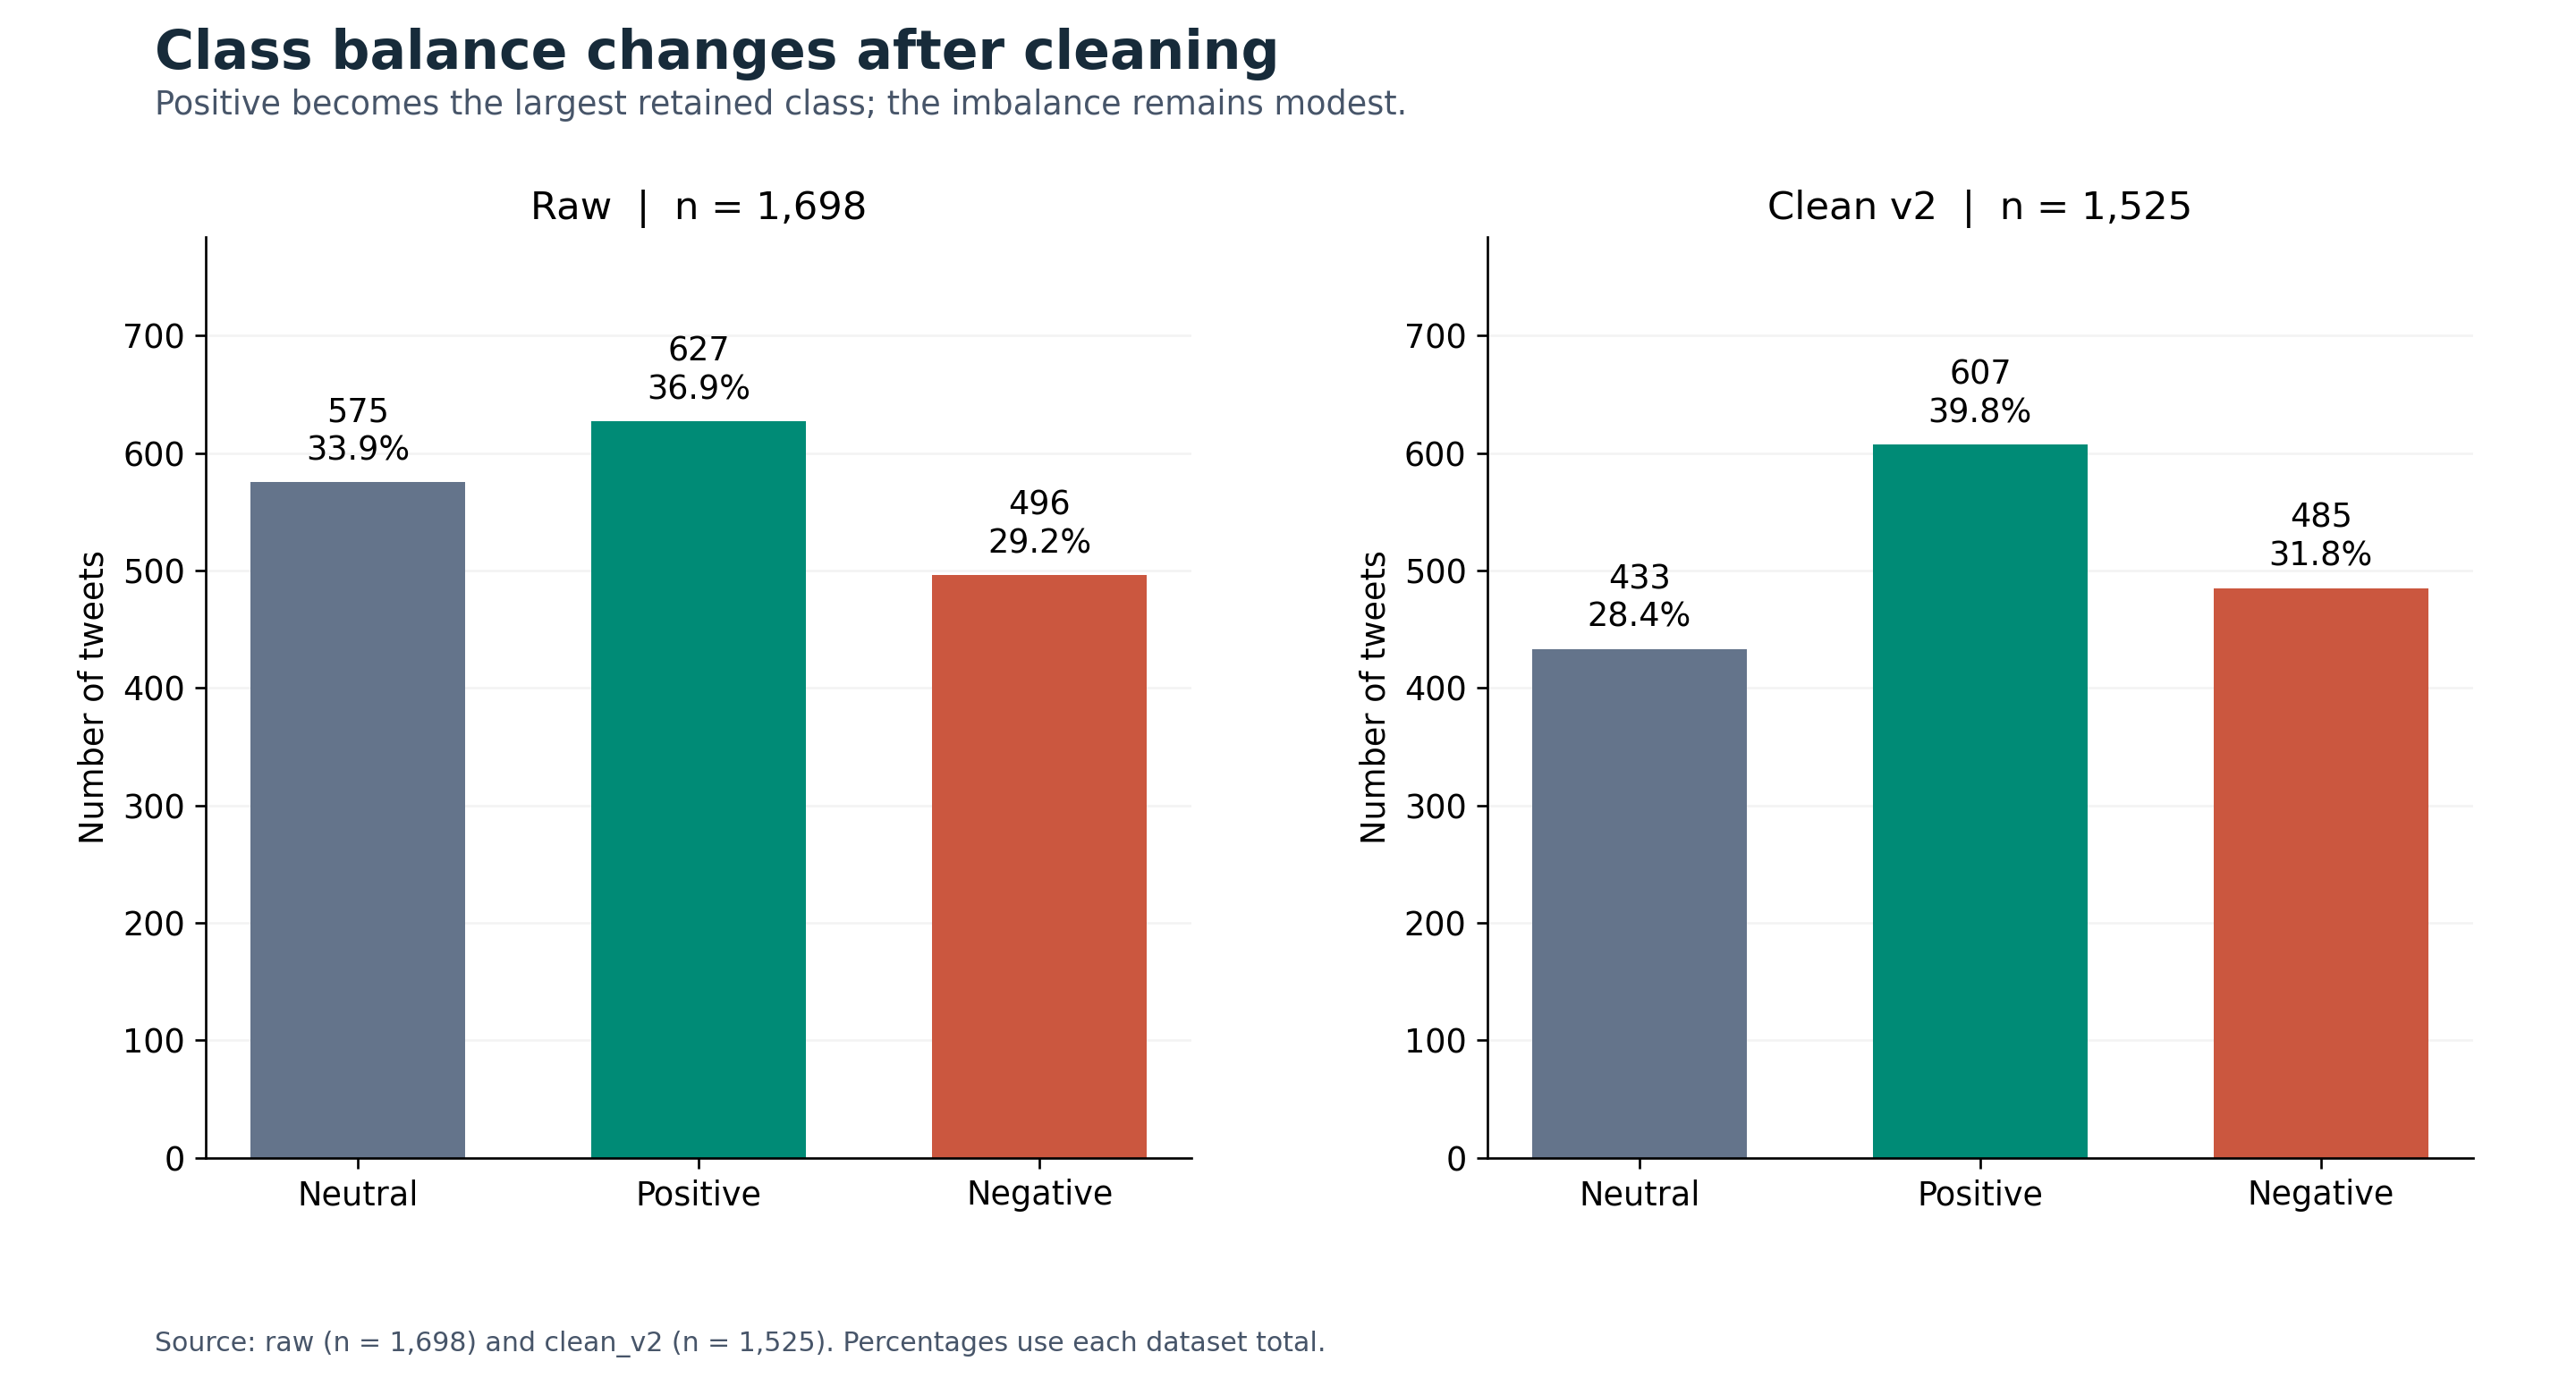

In [4]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_01_class_distribution.png')))


## Figure 2 Text length distributions and outliers


In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,col,title in zip(axes,['char_len','word_len'],['Characters in text_clean','Whitespace tokens in text_clean']):
    bp=ax.boxplot([clean.loc[clean.label_name.eq(l),col] for l in CLASSES],patch_artist=True,
       tick_labels=CLASSES,widths=.5,medianprops={'color':'#172b3a','linewidth':2},
       flierprops={'marker':'.','markersize':3,'markeredgecolor':'#64748b','alpha':.35})
    for box,lab in zip(bp['boxes'],CLASSES): box.set_facecolor(COLORS[lab]); box.set_alpha(.65)
    ax.set_title(title); ax.set_ylabel('Length'); ax.grid(axis='y',alpha=.15)
    for idx,lab in enumerate(CLASSES,1):
        median=clean.loc[clean.label_name.eq(lab),col].median()
        ax.text(idx,median,f' {median:g}',va='bottom',ha='left',fontweight='bold',fontsize=11)
finish(fig,'eda_02_text_lengths','Neutral tweets are shorter in this sample',
       'Median characters: Neutral 86  |  Positive 156  |  Negative 161.',
       'Source: clean_v2. Box = middle 50%; line = median; whiskers = within 1.5 x IQR; dots = remaining observations.\nAll records are shown. A long tweet is not automatically invalid.')



'eda_02_text_lengths.png'

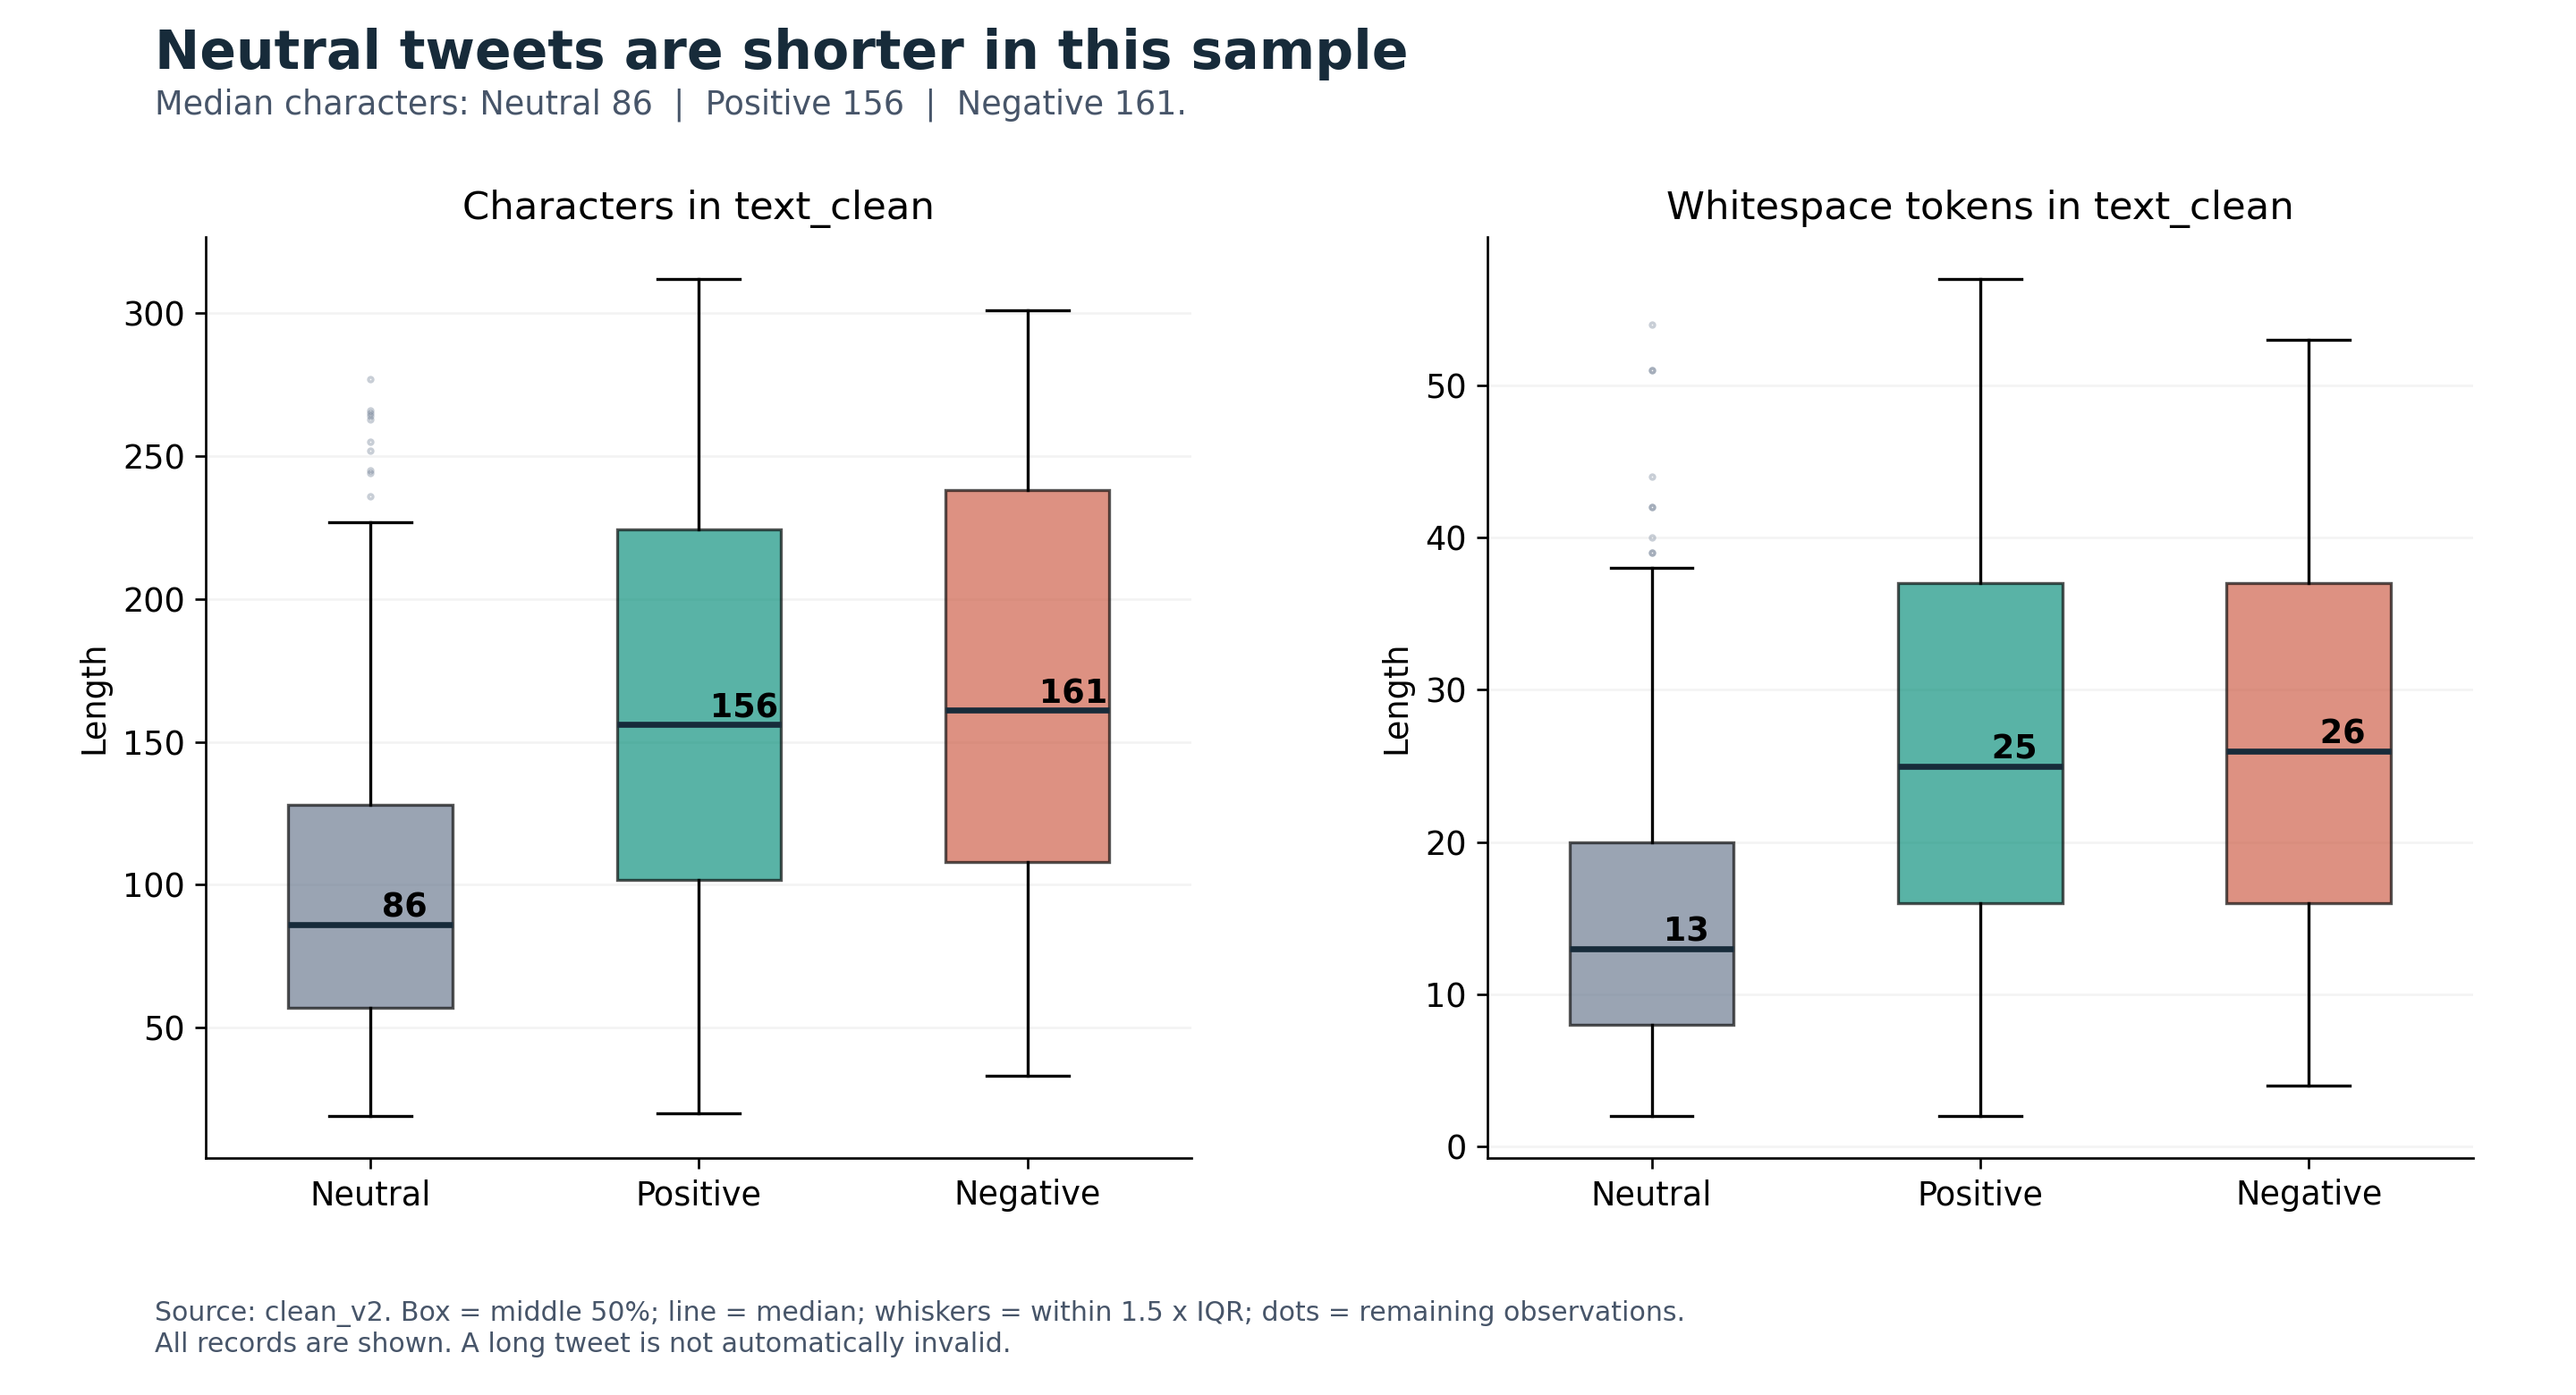

In [6]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_02_text_lengths.png')))


## Figure 3 Hashtag document frequency


In [7]:
hashtag_sets=clean['hashtags'].fillna('').map(lambda s:set(s.lower().split()))
tag_counter=Counter(tag for tags in hashtag_sets for tag in tags)
tags=table(pd.DataFrame([{'hashtag':tag,'tweets':n,'share_of_clean':n/retained} for tag,n in tag_counter.most_common()]),'eda_hashtag_frequency')
top=tags.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,6.5))
ax.barh(['#'+s for s in top.hashtag],top.tweets,color='#287b91',height=.65)
ax.set_xlabel('Tweets containing the hashtag (at most once per tweet)')
ax.set_xlim(0,top.tweets.max()*1.2); ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
for i,row in enumerate(top.itertuples()):ax.text(row.tweets+10,i,f'{row.tweets:,}  ({row.share_of_clean:.1%})',va='center',fontsize=10)
fig.subplots_adjust(left=.22)
finish(fig,'eda_03_hashtags','Which hashtags dominate the retained tweets',
       'Collection hashtags describe the sampling frame; frequency does not establish sentiment.',
       'Source: clean_v2 hashtags column; denominator = 1,525 retained tweets. Tags are case-normalized and deduplicated within tweets.')



'eda_03_hashtags.png'

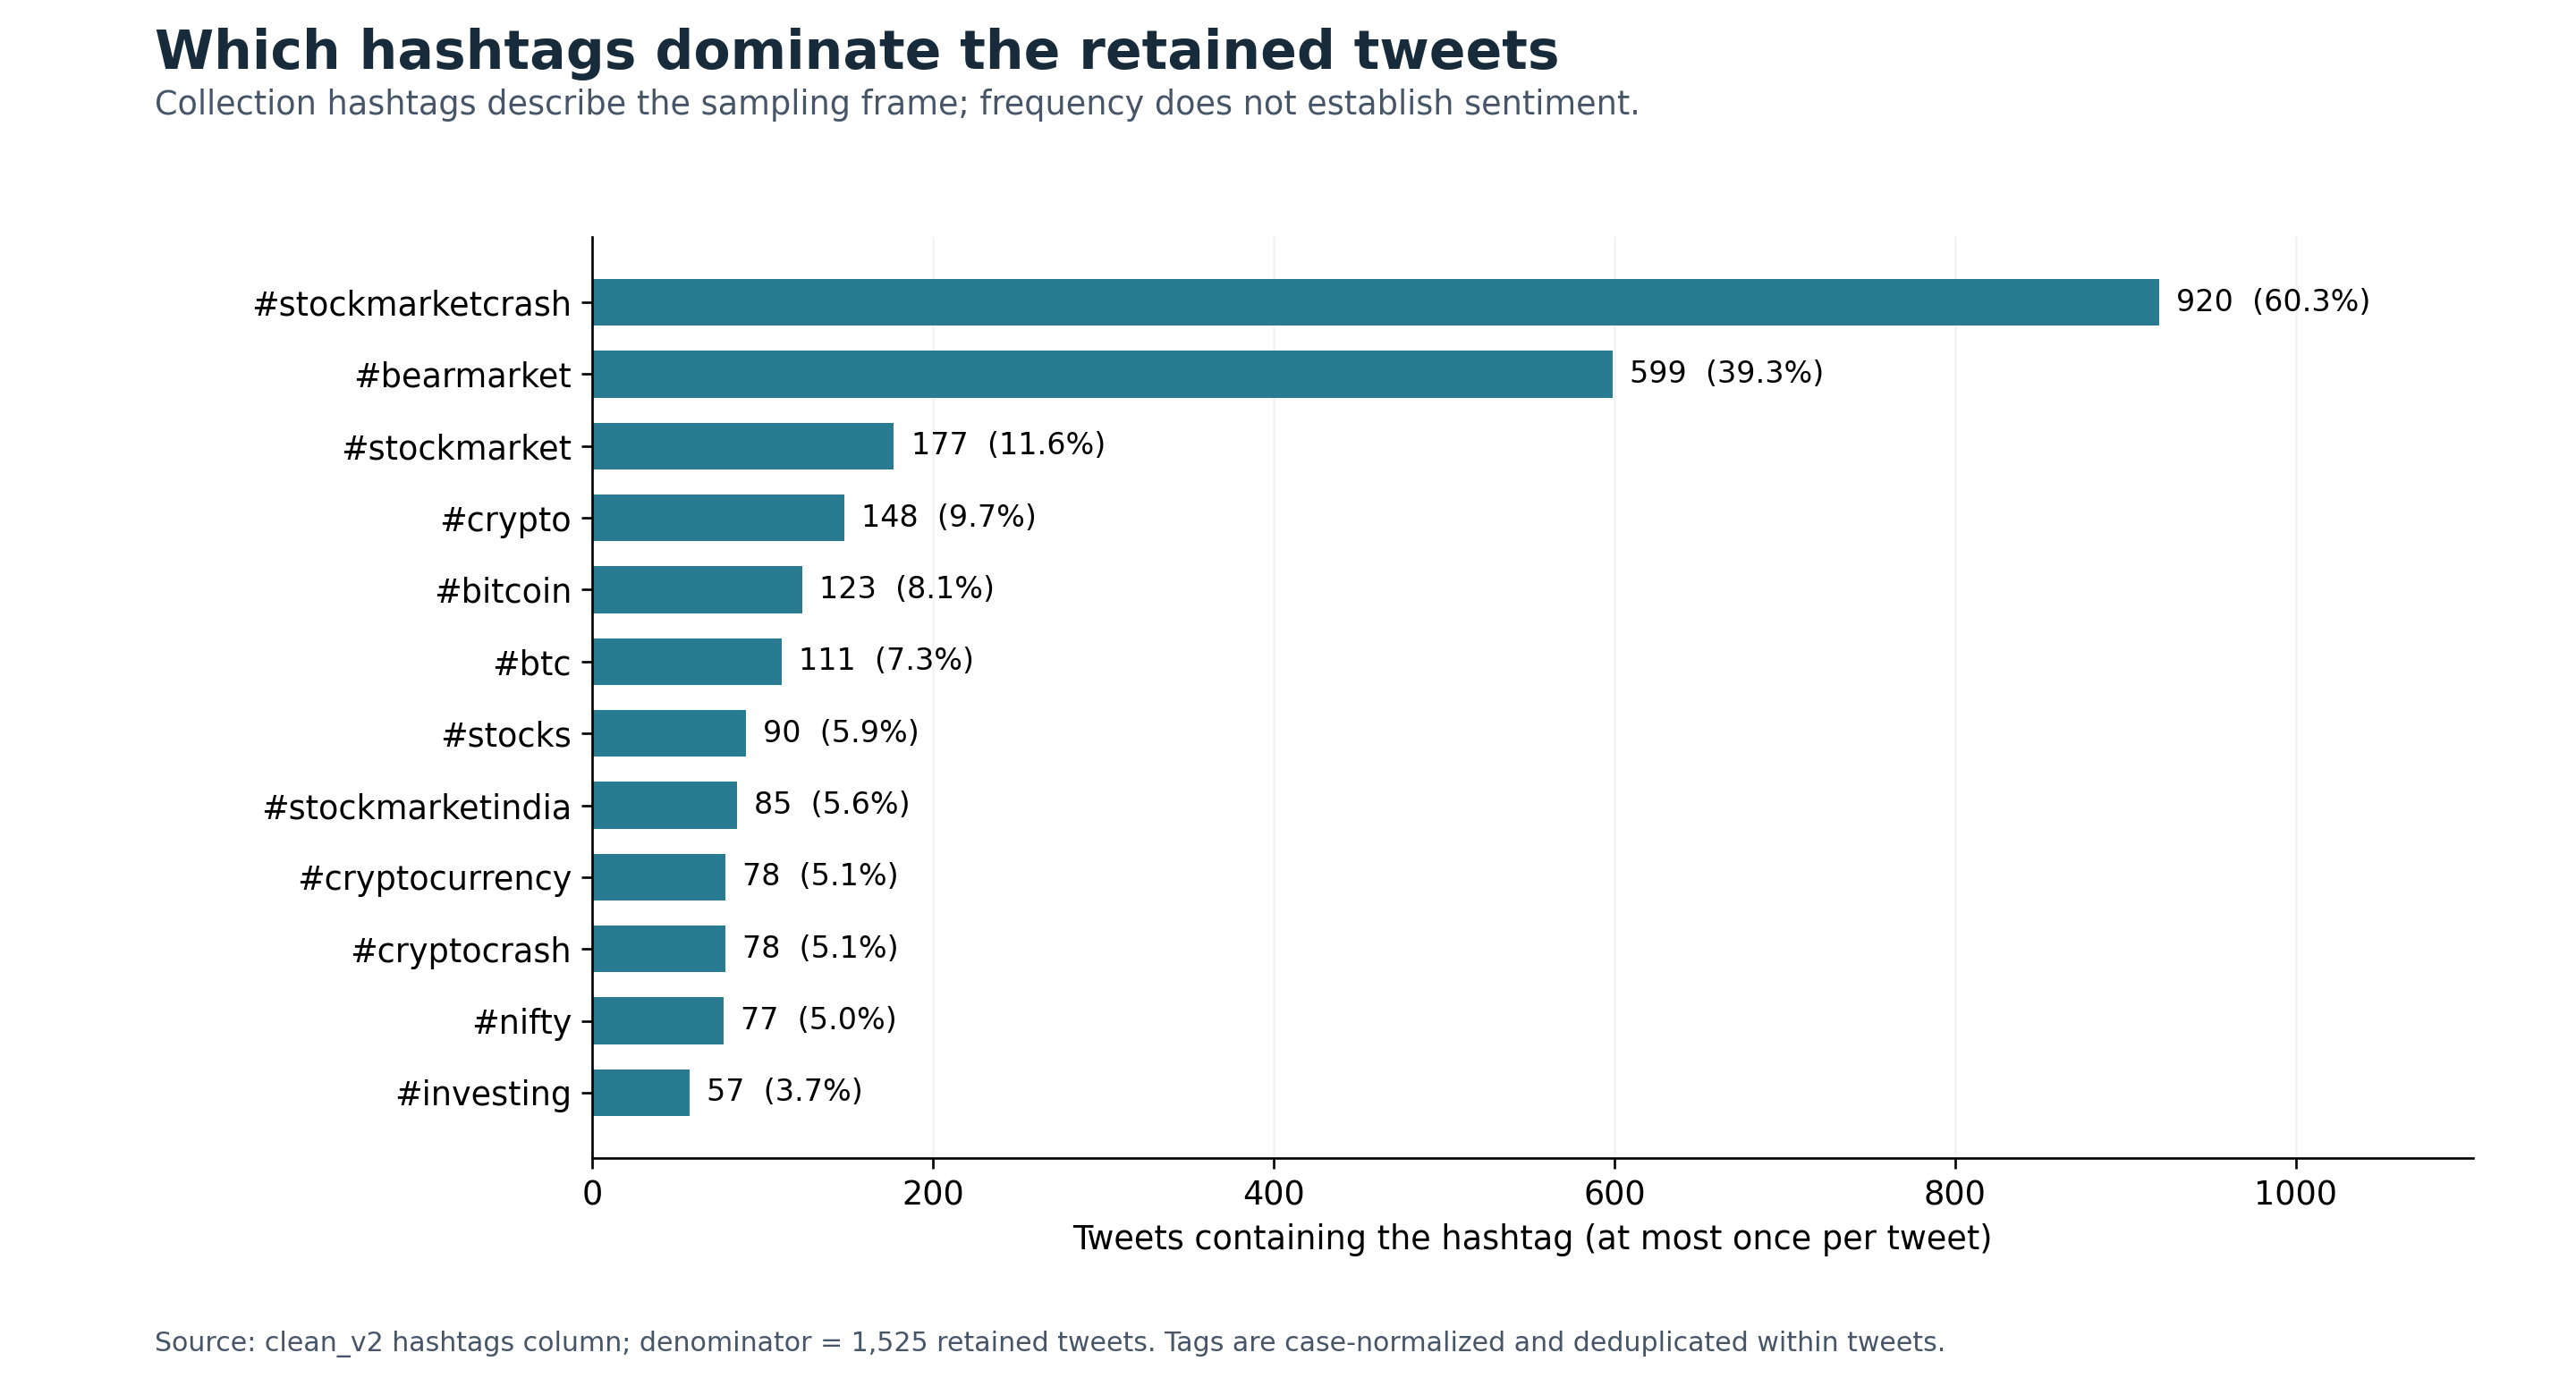

In [8]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_03_hashtags.png')))


## Figure 4 Vocabulary by sentiment using document frequency


In [9]:
# text_norm is already lemmatized by the team. Exclusions apply only to this descriptive chart.
EXCLUDED={'stockmarketcrash','bearmarket','user','http','https','www','co','rt','amp'}
def content_set(text):
    return {w for w in re.findall(r'[a-z]+',text.lower()) if len(w)>=2 and w not in EXCLUDED}
word_sets=clean['text_norm'].map(content_set)
vocab_rows=[]
for lab in CLASSES:
    counter=Counter(w for words in word_sets[clean.label_name.eq(lab)] for w in words)
    n=int(clean.label_name.eq(lab).sum())
    for word,count in sorted(counter.items(),key=lambda p:(-p[1],p[0])):
        vocab_rows.append({'sentiment':lab,'word':word,'tweets':count,'class_n':n,'share_within_class':count/n})
vocab=table(pd.DataFrame(vocab_rows),'eda_vocabulary_by_class')
bigram_rows=[]
for lab in CLASSES:
    counter=Counter()
    for text in clean.loc[clean.label_name.eq(lab),'text_norm']:
        words=re.findall(r'[a-z]+',text.lower())
        counter.update(set(a+' '+b for a,b in zip(words,words[1:])
                           if len(a)>=2 and len(b)>=2 and a not in EXCLUDED and b not in EXCLUDED))
    for phrase,n in sorted(counter.items(),key=lambda p:(-p[1],p[0])):
        bigram_rows.append({'sentiment':lab,'normalized_bigram':phrase,'tweets':n,
                           'share_within_class':n/int(clean.label_name.eq(lab).sum()),
                           'definition':'Adjacent tokens in supplied text_norm; normalization can remove intervening raw words'})
table(pd.DataFrame(bigram_rows),'eda_bigrams_by_class')
fig,axes=plt.subplots(1,3,figsize=(14,6.5))
for ax,lab in zip(axes,CLASSES):
    sub=vocab[vocab.sentiment.eq(lab)].head(10).iloc[::-1]
    ax.barh(sub.word,sub.share_within_class,color=COLORS[lab],height=.65)
    ax.set_xlim(0,.4); ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f'{lab}  |  n = {int(clean.label_name.eq(lab).sum())}')
    ax.set_xlabel('Share of tweets within class'); ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
    for i,row in enumerate(sub.itertuples()):ax.text(row.share_within_class+.006,i,f'{row.share_within_class:.1%}',va='center',fontsize=9)
finish(fig,'eda_04_vocabulary','Frequent content words within each sentiment class',
       'Document frequency avoids counting a repeated word multiple times in the same tweet.',
       'Source: clean_v2 text_norm. Existing lemmatization retained; collection words and technical remnants excluded for this chart only.\nExclusions: stockmarketcrash, bearmarket, user, http, https, www, co, rt, amp. Words are descriptive, not model explanations.')



'eda_04_vocabulary.png'

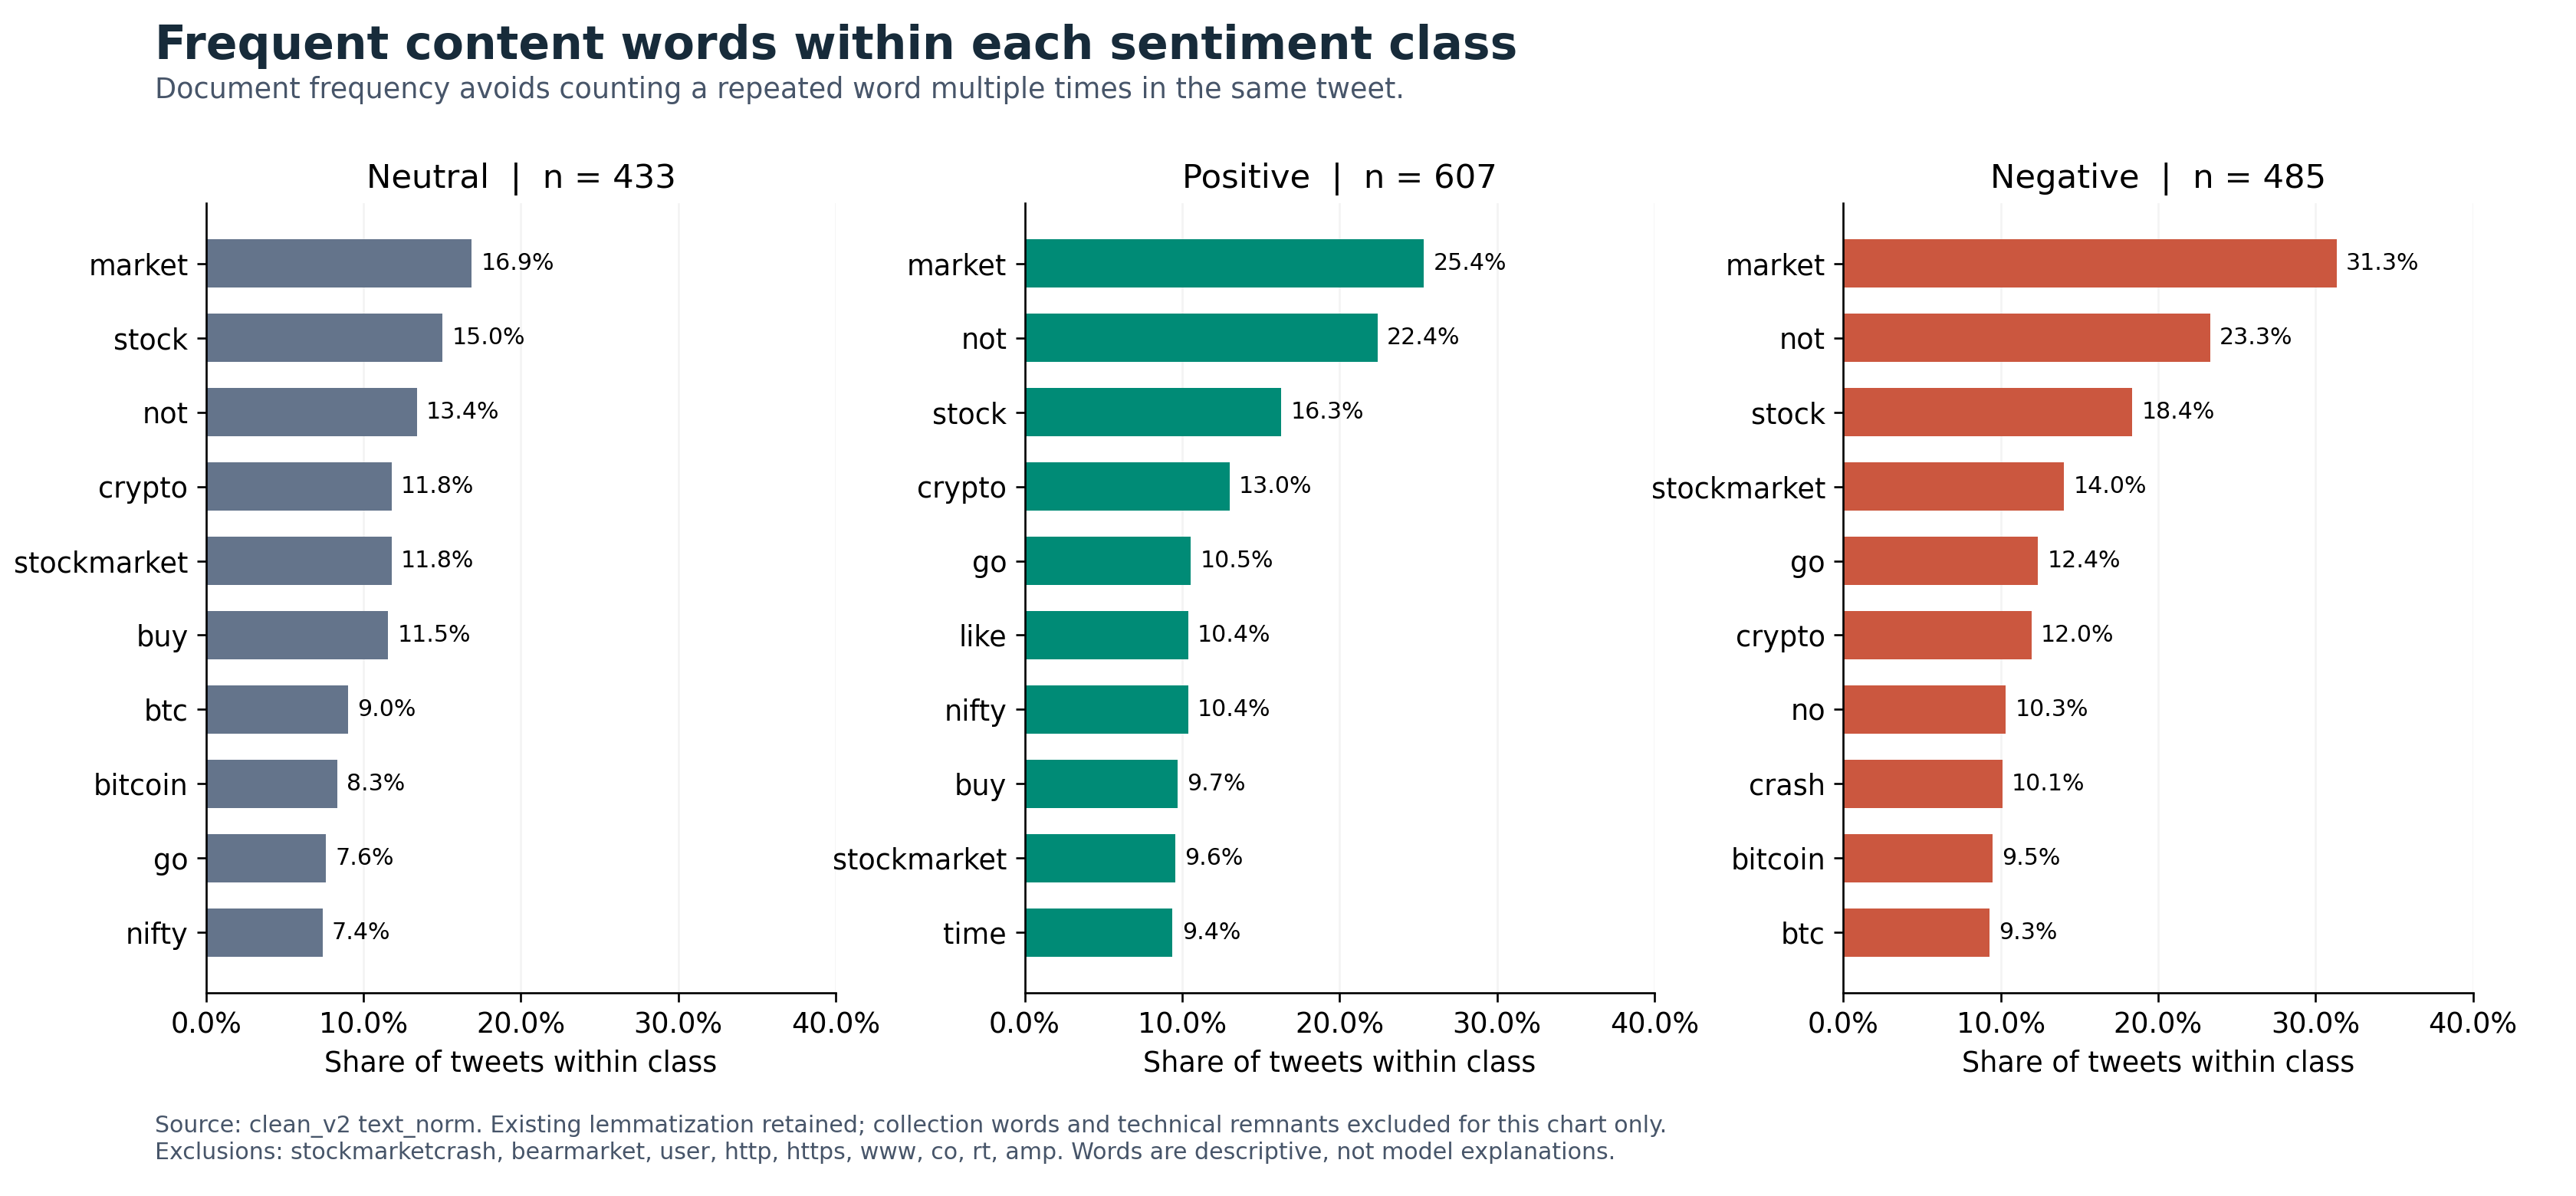

In [10]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_04_vocabulary.png')))


## Figure 5 Overlapping market mentions and sentiment


In [11]:
market_flags={'Crypto':'domain_crypto','US equities':'domain_us','India':'domain_india'}
market_rows=[]
for market,flag in market_flags.items():
    sub=clean[clean[flag].eq(1)]
    for lab in CLASSES:
        n=int(sub.label_name.eq(lab).sum())
        market_rows.append({'market':market,'sentiment':lab,'tweets':n,'market_n':len(sub),'share_within_market':n/len(sub)})
markets=table(pd.DataFrame(market_rows),'eda_market_sentiment')
flags=clean[list(market_flags.values())].sum(axis=1)
coverage=table(pd.DataFrame({'market_flags_set':[0,1,2,3],
                            'tweets':[(flags==n).sum() for n in range(4)]}),'eda_market_coverage')
fig,ax=plt.subplots(figsize=(12,6.5))
left=np.zeros(3)
names=list(market_flags)
for lab in CLASSES:
    sub=markets[markets.sentiment.eq(lab)].set_index('market').loc[names]
    vals=sub.share_within_market.to_numpy()
    ax.barh(names,vals,left=left,color=COLORS[lab],height=.55,label=lab)
    for i,(start,v,n) in enumerate(zip(left,vals,sub.tweets)):
        if v>.06:ax.text(start+v/2,i,f'{v:.1%}\n(n={n})',ha='center',va='center',color='white',fontsize=11,fontweight='bold')
    left+=vals
ax.set_yticks(range(3),[f'{m}\n(n={int(markets[markets.market.eq(m)].market_n.iloc[0])})' for m in names])
ax.set_xlim(0,1); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlabel('Sentiment share within flagged market')
ax.invert_yaxis()
handles,labels=ax.get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.56,.845),ncol=3,frameon=False)
finish(fig,'eda_05_market_sentiment','Sentiment across rule tagged market mentions',
       'These are overlapping hashtag and cashtag subsets, not representative samples of whole markets.',
       f'Source: clean_v2 domain flags. {int((flags.eq(0)).sum())} tweets have no market flag; {int(flags.gt(1).sum())} have multiple flags.\nEach row has its own denominator. No geographic location, return or time trend is inferred.')



'eda_05_market_sentiment.png'

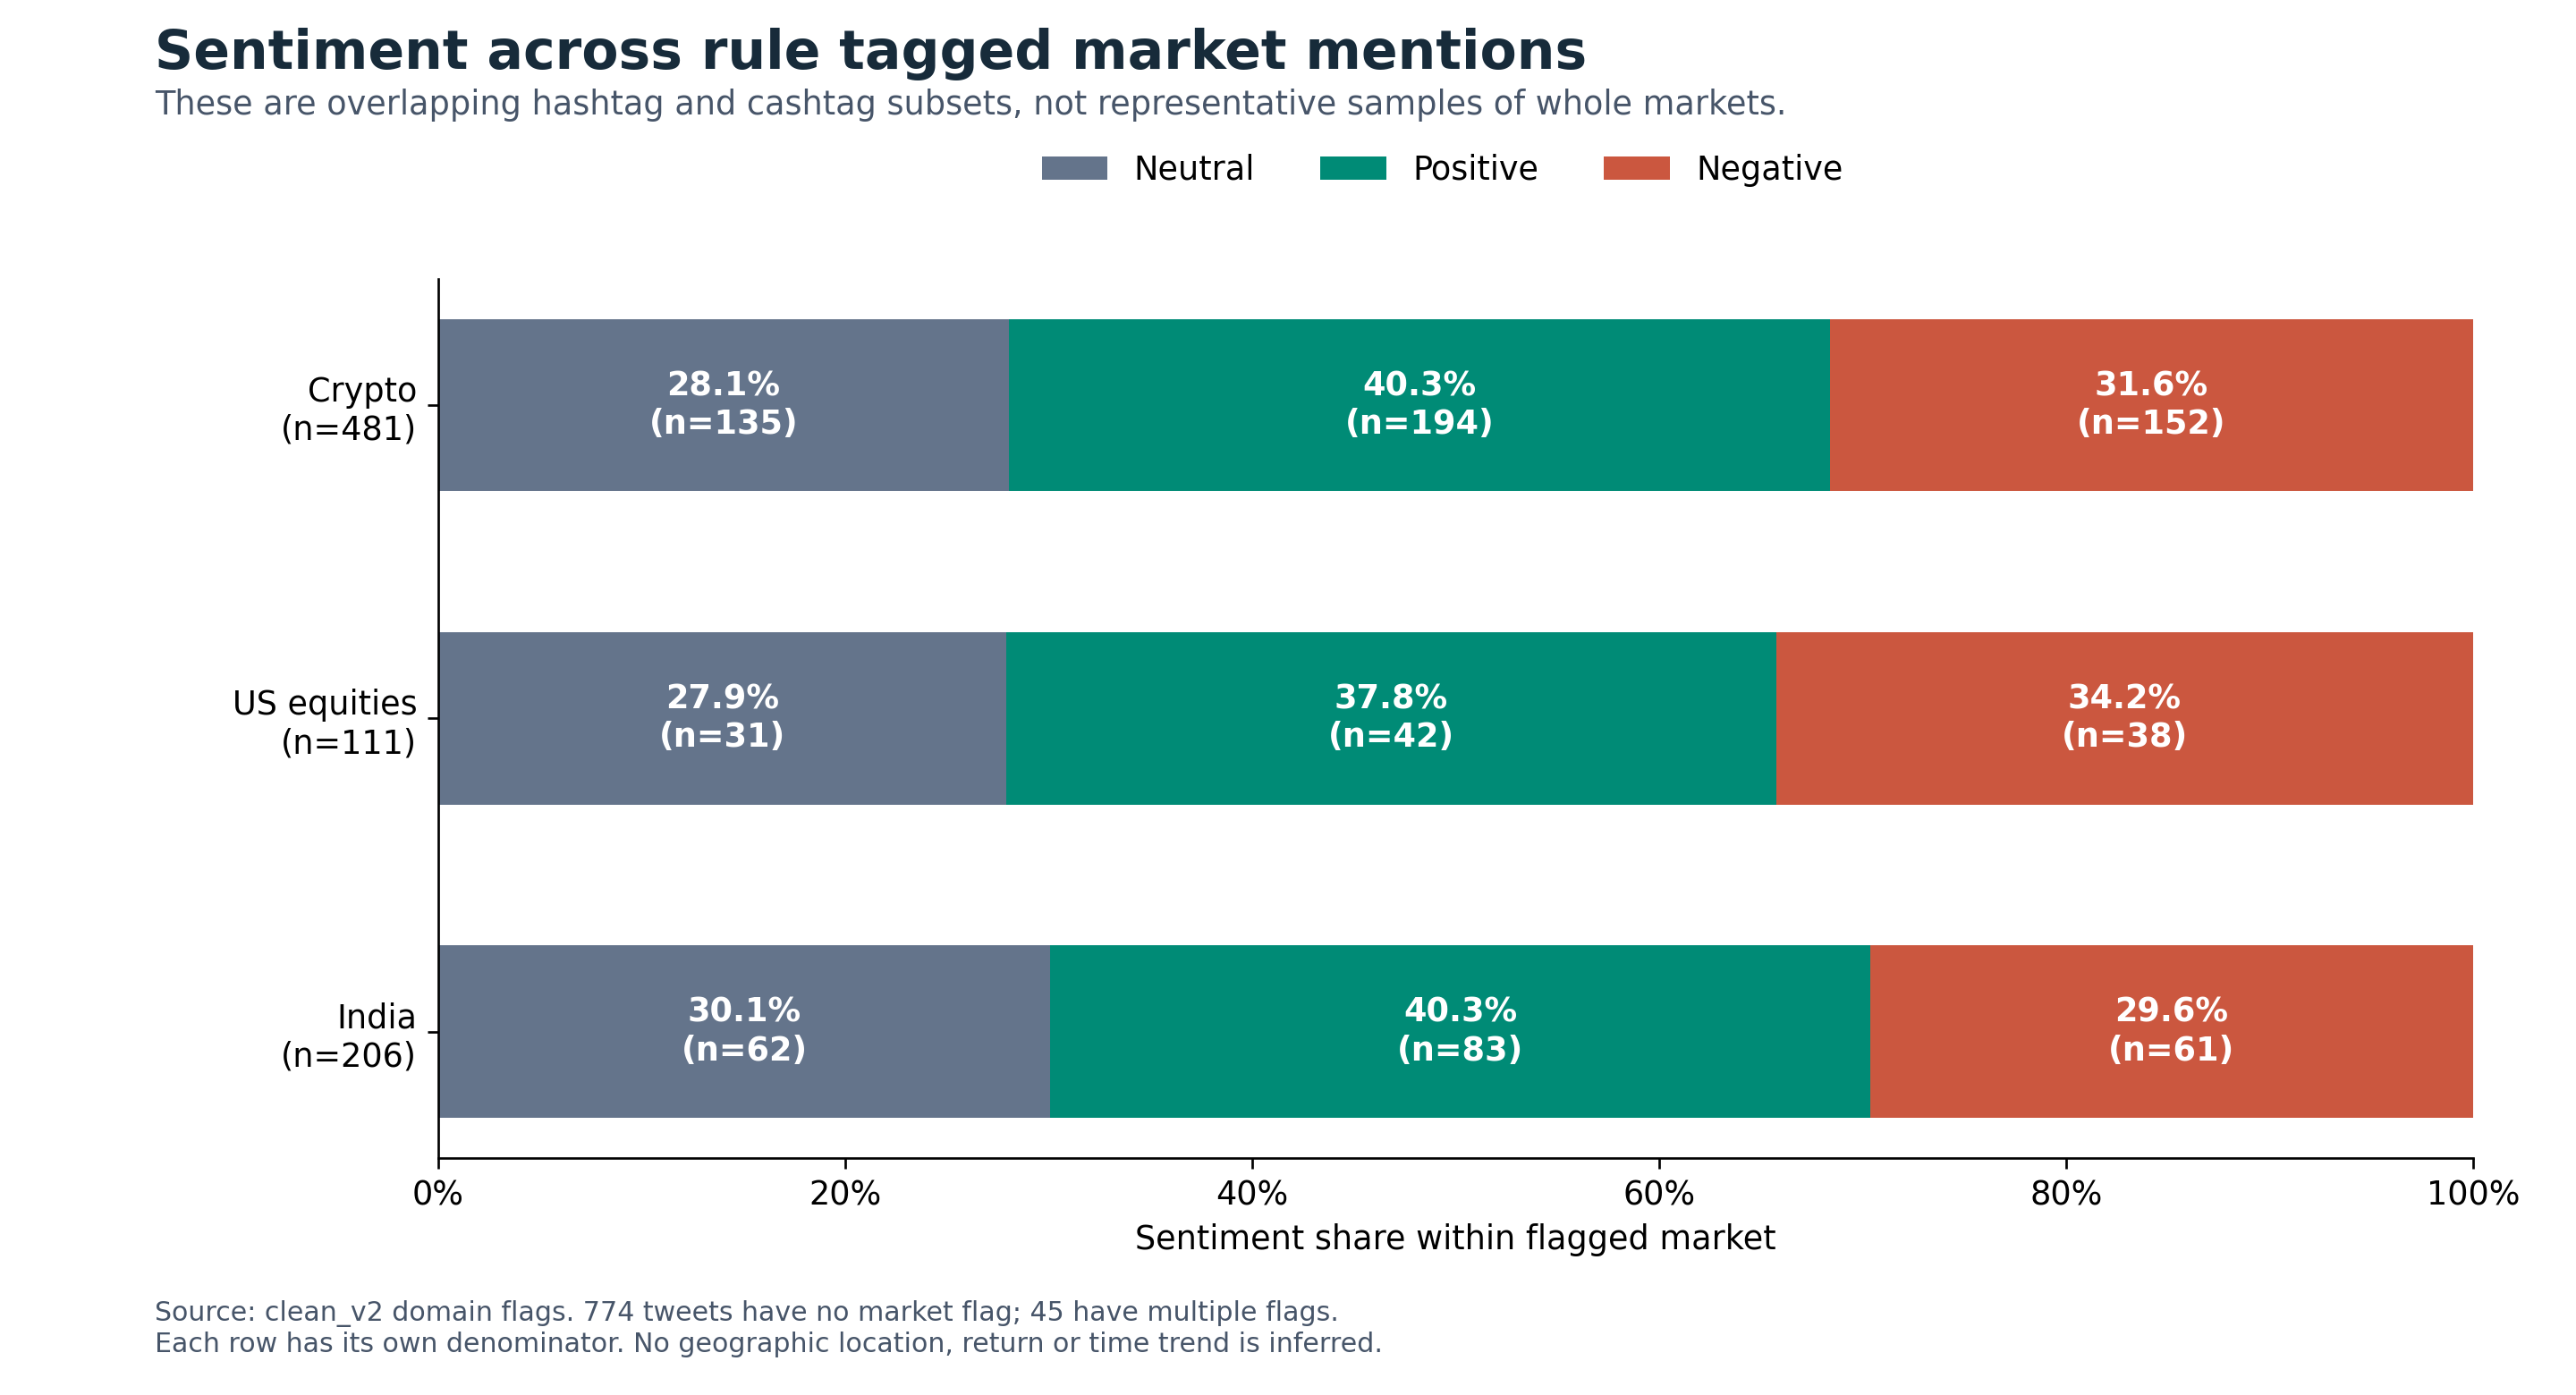

In [12]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_05_market_sentiment.png')))


## Figure 6 Sentiment is categorical and is compared using conditional proportions


In [13]:
clean['length_bin']=pd.cut(clean['char_len'],[-np.inf,80,140,220,np.inf],labels=['<=80','81-140','141-220','>220'])
clean['hashtag_bin']=pd.cut(clean['n_hashtags'],[-np.inf,1,3,5,np.inf],labels=['0-1','2-3','4-5','6+'])
bin_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,col,title in zip(axes,['length_bin','hashtag_bin'],['Characters in text_clean','Number of hashtags']):
    ct=pd.crosstab(clean[col],clean['label_name'],dropna=False).reindex(columns=CLASSES,fill_value=0)
    n=ct.sum(axis=1); props=ct.div(n,axis=0).fillna(0)
    x=np.arange(len(ct)); bottom=np.zeros(len(ct))
    for lab in CLASSES:
        vals=props[lab].to_numpy(); ax.bar(x,vals,bottom=bottom,color=COLORS[lab],label=lab,width=.68)
        for i,(b,v,count) in enumerate(zip(bottom,vals,ct[lab])):
            if v>=.14: ax.text(i,b+v/2,f'{v:.0%}',ha='center',va='center',color='white',fontweight='bold',fontsize=10)
            bin_rows.append({'feature':col,'bin':str(ct.index[i]),'sentiment':lab,'tweets':int(count),'bin_n':int(n.iloc[i]),'share_within_bin':float(v)})
        bottom+=vals
    ax.set_xticks(x,[f'{s}\n(n={int(nn)})' for s,nn in zip(ct.index,n)]);ax.set_ylim(0,1)
    ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylabel('Sentiment share within bin');ax.set_xlabel(title)
    ax.set_title(title)
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.845),ncol=3,frameon=False)
bins=table(pd.DataFrame(bin_rows),'eda_feature_sentiment_bins')
finish(fig,'eda_06_feature_relationships','How sentiment composition varies with text features',
       'Fixed descriptive bins show associations without treating labels 0, 1 and 2 as numerical scores.',
       'Source: clean_v2. Percentages use the n shown below each bin. Bins are descriptive choices, not tuned model thresholds.\nAssociations may reflect topic and label generation; no causal or predictive claim is made.')



'eda_06_feature_relationships.png'

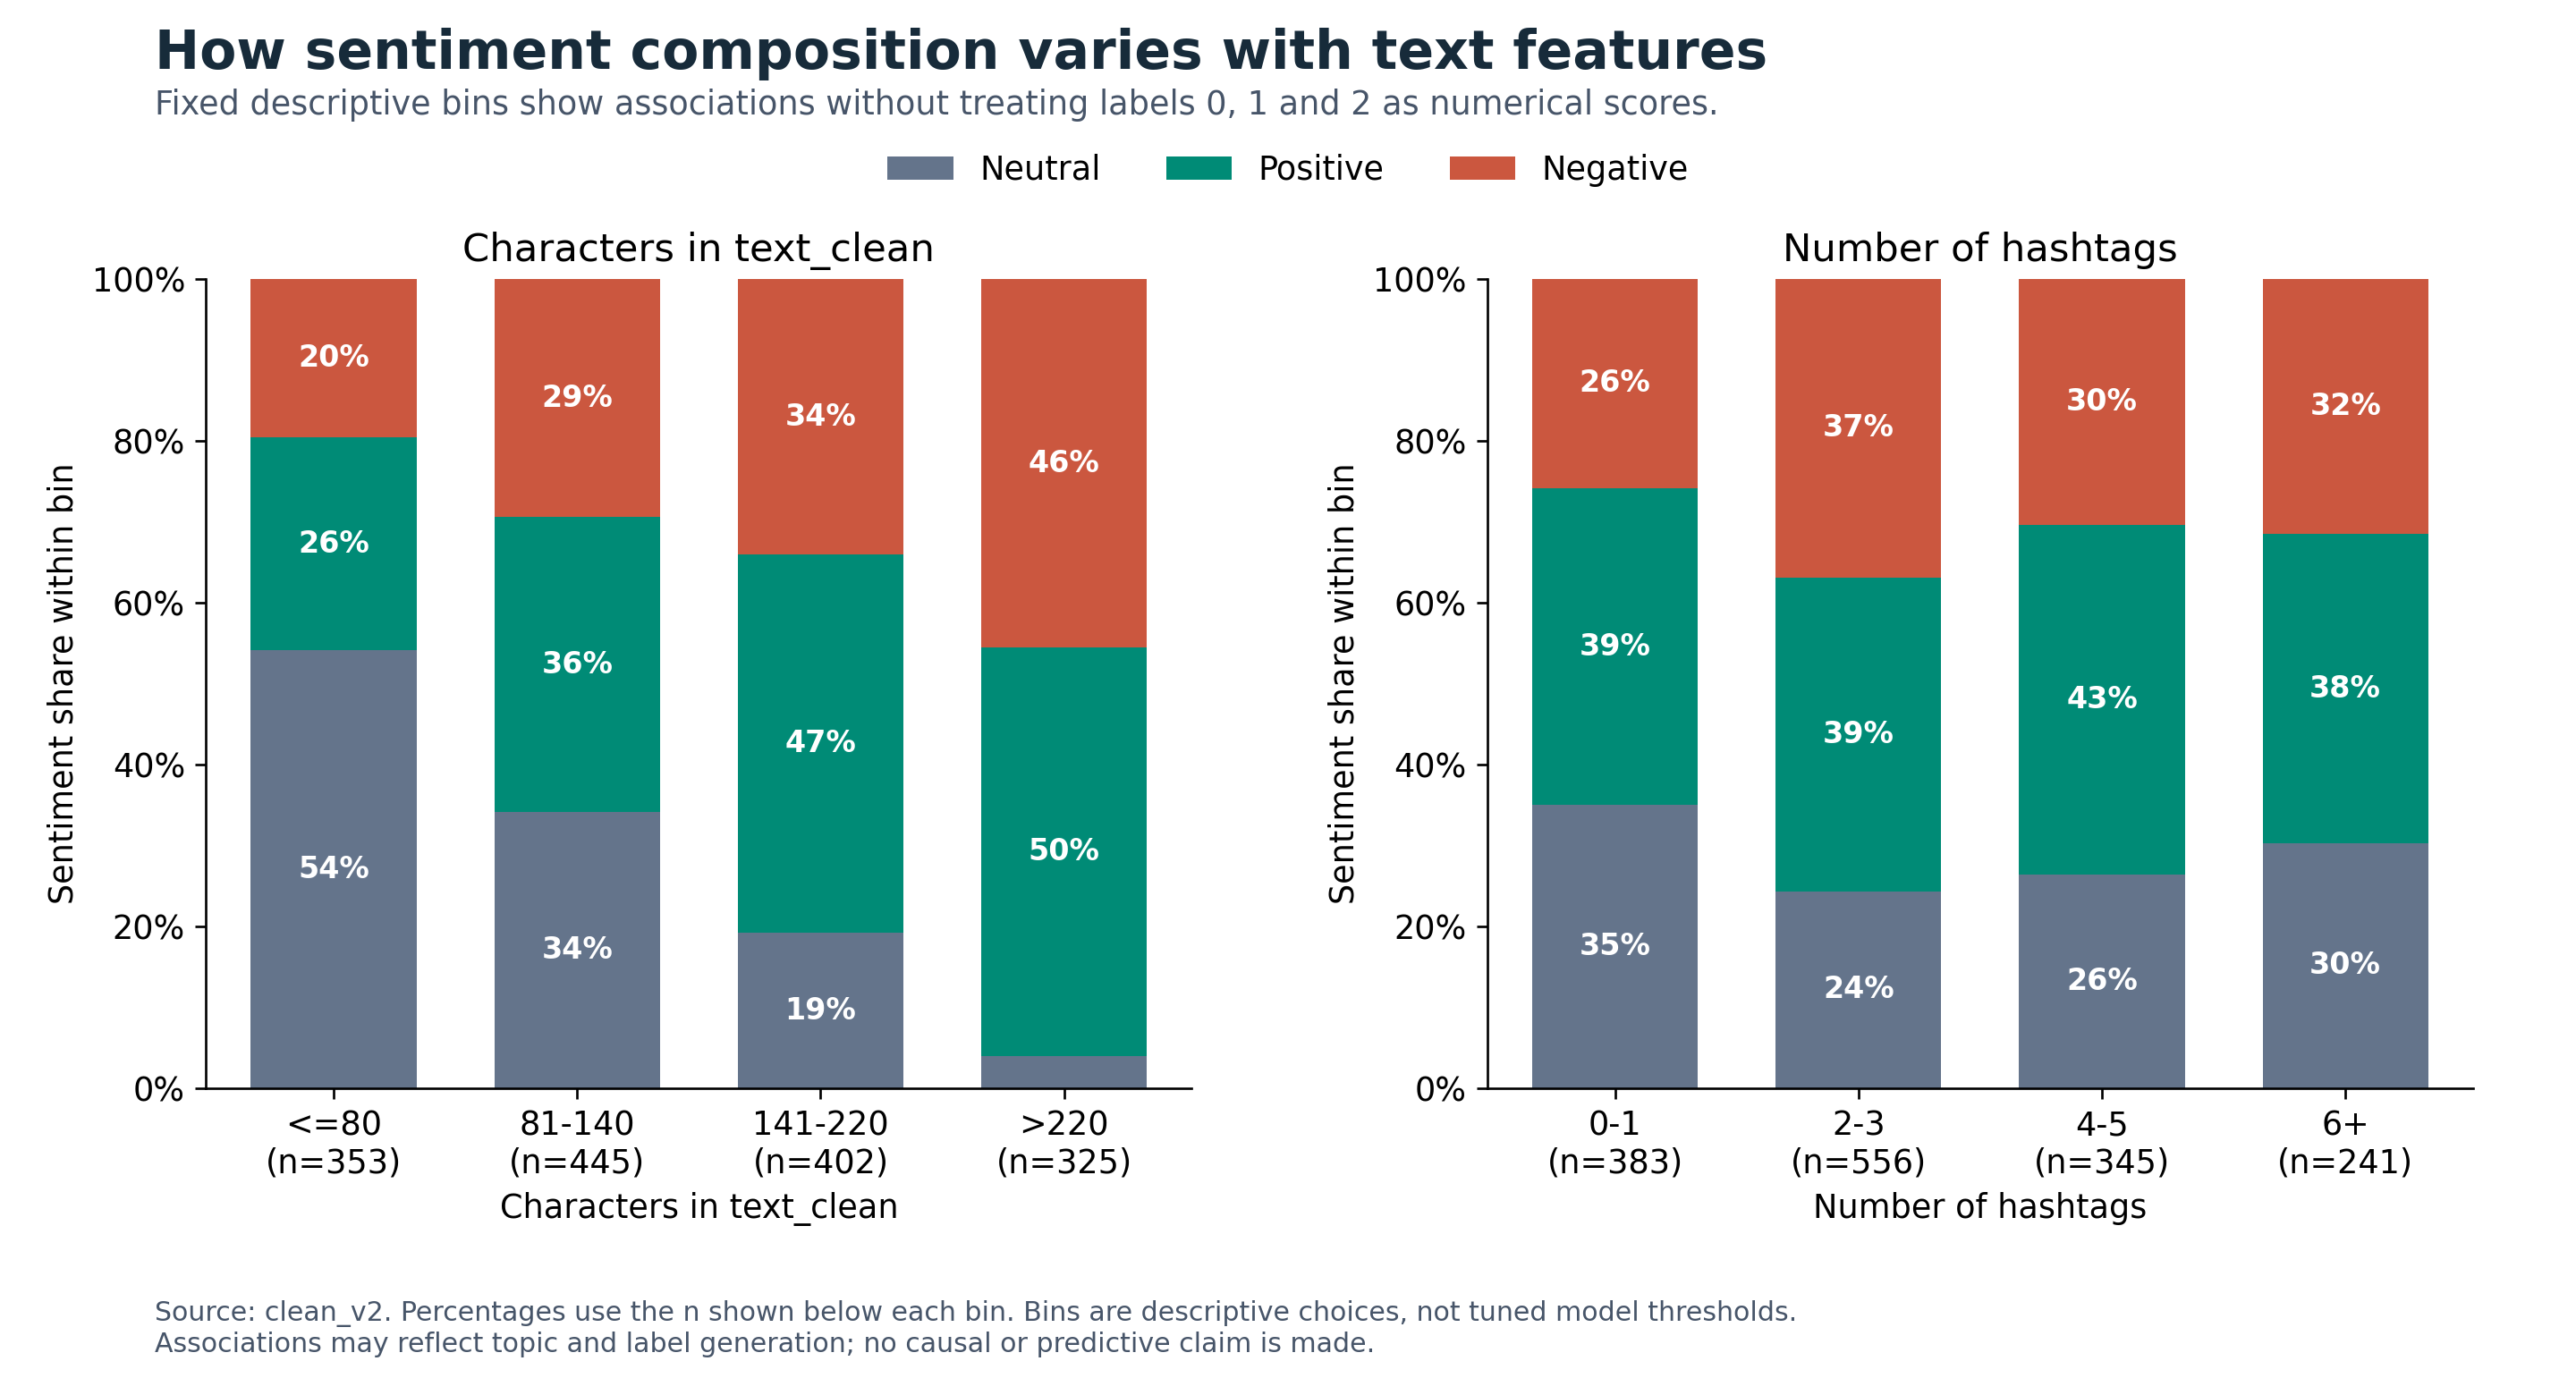

In [14]:
from IPython.display import display, Image
display(Image(filename=str(FIGURES / 'eda_06_feature_relationships.png')))


## Save audit metadata and an English report


In [15]:
raw_counts=raw['label_name'].value_counts().reindex(CLASSES)
clean_counts=clean['label_name'].value_counts().reindex(CLASSES)
manifest={'author':'YANG Qitian (24128112D)','task':'Member 3 EDA handoff for 4 November 2026',
  'data_version':'clean_v2','raw_n':len(raw),'clean_n':retained,'removed_n':removed,
  'class_order':CLASSES,'raw_counts':raw_counts.to_dict(),'clean_counts':clean_counts.to_dict(),
  'inputs':{k:{'filename':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for k,p in INPUTS.items()},
  'environment':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__},
  'limits':['Full supplied snapshot used for descriptive course EDA; no model fitting, tuning or test-score inspection.',
            'Market subsets overlap and are inferred by supplied rules.',
            'VADER label provenance is the team hypothesis, not independently confirmed by this EDA.',
            'No price, return, timestamp or user identifiers are available as dedicated source columns.'],
  'word_chart_exclusions':sorted(EXCLUDED),'randomness':'None; deterministic summaries and plots.'}
(OUTPUT/'eda_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
imbalance=float(clean_counts.max()/clean_counts.min())
retention=retained/len(raw)
raw_neutral=raw_counts['Neutral']/len(raw)
clean_neutral=clean_counts['Neutral']/retained
median_clean=float(clean.char_len.median())
label_lengths={lab:float(clean.loc[clean.label_name.eq(lab),'char_len'].median()) for lab in CLASSES}
market_text='; '.join(f"{m}: {int(markets[(markets.market.eq(m))&(markets.sentiment.eq('Positive'))].tweets.iloc[0])}/{int(markets[markets.market.eq(m)].market_n.iloc[0])} Positive ({markets[(markets.market.eq(m))&(markets.sentiment.eq('Positive'))].share_within_market.iloc[0]:.1%})" for m in market_flags)
short_neutral=bins[(bins.feature.eq('length_bin'))&(bins['bin'].eq('<=80'))&(bins.sentiment.eq('Neutral'))].iloc[0]
long_neutral=bins[(bins.feature.eq('length_bin'))&(bins['bin'].eq('>220'))&(bins.sentiment.eq('Neutral'))].iloc[0]
def image_data(name):return 'data:image/png;base64,'+base64.b64encode((FIGURES/name).read_bytes()).decode()
def fig_html(number,name,caption):
    return f'<figure><img src="{image_data(name)}" alt="Figure {number} {html.escape(caption)}"><figcaption>Figure {number}. {html.escape(caption)}</figcaption></figure>'
STYLE="""
body{max-width:1050px;margin:40px auto;padding:0 28px;font:16px/1.7 Arial,"Microsoft YaHei",sans-serif;color:#192b3b;background:white}h1{font-size:30px;line-height:1.25;color:#111}h2{font-size:23px;margin-top:36px;color:#111}h3{font-size:19px;color:#111}p{margin:13px 0}.meta{color:#526475}.lead{font-size:18px}.note{padding:14px 18px;background:#eef4f6;border-radius:4px}table{border-collapse:collapse;width:100%;font-size:14px;margin:18px 0}th,td{border:1px solid #d9d9d9;padding:9px 11px;text-align:left;vertical-align:top}th{background:#e7eff4;color:#111}tr:nth-child(even){background:#f7f9fa}img{max-width:100%;height:auto}figure{margin:28px 0}figcaption{font-size:14px;color:#475569}code{background:#f1f5f9;padding:2px 5px}li{margin:8px 0}a{color:#176f88}details{padding:12px;background:#f7f9fa}section{break-inside:auto}@media print{body{font-size:11pt;margin:0;max-width:none}h2{break-after:avoid}figure{break-inside:avoid}table{font-size:9pt}a{color:#111;text-decoration:none}}
"""
summary_table=counts.rename_axis('Sentiment').reset_index()
summary_table['Clean share']=[f'{clean_counts[c]/retained:.1%}' for c in CLASSES]
quality_report=quality.iloc[:10].copy()
english=f"""<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>DSAI4205 Member 3 Exploratory Data Analysis</title><style>{STYLE}</style><body>
<h1>Exploratory Data Analysis of Stock Market Crash Tweets</h1>
<p class="meta">DSAI4205 DataVinci | YANG Qitian 24128112D | Member 3 EDA contribution | Handoff 4 November 2026</p>
<p class="lead">We examined 1,698 supplied tweets and the 1,525 records retained in clean_v2. The retained data show modest class imbalance and shorter Neutral tweets. Hashtag and market comparisons describe this sample and require cautious interpretation because the collection is topic filtered and the label source remains uncertain.</p>
<h2>2 Exploratory Data Analysis</h2>
<h3>2 1 Data quality and descriptive statistics</h3>
<p>The unit of analysis is one tweet, not one investor or one trading day. The source CSV contains text and text_sentiment, coded as 0 Neutral, 1 Positive and 2 Negative. We checked missing and blank values, label validity, duplicate text and the retained IDs against the original records. No text or label values were missing, and all source labels were valid. There were nine exact duplicate copies beyond their first occurrence.</p>
<p>The supplied cleaning pipeline retained {retained:,} records ({retention:.1%}) and excluded {removed} ({1-retention:.1%}). The exclusions were 102 non-English records, 39 records without lexical content, 21 records with unreadable encoding and 11 duplicate copies (nine exact and two content duplicates). These counts were reproduced from keep and drop_reason in clean_v2_all.csv; this EDA did not rerun or change the cleaning rules.</p>
<p><strong>Table 3 Data quality summary</strong></p>{quality_report.to_html(index=False,border=0)}
<p>Raw text has a median length of {raw.char_len.median():g} characters, compared with {median_clean:g} characters for text_clean in the retained set. This is not a paired estimate of the cleaning effect because both the text representation and the retained population change. The retained data contain {clean.group_id.nunique():,} related-text groups; {int(group_sizes[group_sizes.gt(1)].sum())} records belong to {int(group_sizes.gt(1).sum())} non-singleton groups. Related records should stay in the same partition and validation fold.</p>
<p>The supplied flag emoji_lost is set for {int(clean.emoji_lost.sum())} retained records. It indicates lost source characters, rather than recoverable emoji counts. The team cleaning and label-analysis notes suggest that the given labels may have been produced with VADER. This remains a provenance hypothesis; no independent human-label audit was conducted here, and agreement with supplied labels should not be equated with financial sentiment validity.</p>
<h3>2 2 Class distribution</h3>
{summary_table.to_html(index=False,border=0)}
{fig_html(1,'eda_01_class_distribution.png','Class distribution in the raw and retained datasets')}
<p>Positive accounts for 607 retained tweets (39.8%), Negative for 485 (31.8%) and Neutral for 433 (28.4%). The largest-to-smallest class ratio is {imbalance:.2f}. This is modest imbalance. Accuracy alone may conceal differences between classes, so subsequent comparisons should include Macro F1 and per-class precision and recall. EDA does not establish that weighting or oversampling will improve performance.</p>
<p>The Neutral share falls from {raw_neutral:.1%} to {clean_neutral:.1%}, a decrease of {(raw_neutral-clean_neutral)*100:.1f} percentage points. This is a change in dataset composition caused by exclusions, rather than evidence of changing market sentiment over time.</p>
<h3>2 3 Text characteristics</h3>
{fig_html(2,'eda_02_text_lengths.png','Character and whitespace token lengths by sentiment')}
<p>Neutral tweets have a median of 86 characters and 13 whitespace tokens, compared with 156 characters and 25 tokens for Positive and 161 characters and 26 tokens for Negative. This descriptive separation suggests that length may be useful as an auxiliary feature, although it could also reflect annotation and topic differences. The boxplots retain all observations. Points outside the whiskers are distributional outliers and are not automatically errors. Transformer sequence limits should be selected from tokenizer lengths in the development data; whitespace tokens are not a substitute.</p>
{fig_html(3,'eda_03_hashtags.png','Most frequent hashtags measured by tweet document frequency')}
<p>Each hashtag is counted at most once per tweet and divided by all {retained:,} retained tweets. Topic collection tags dominate the ranking, so their frequency largely reflects how the data were collected. It should not be interpreted as a measure of market-wide attention or emotional intensity.</p>
{fig_html(4,'eda_04_vocabulary.png','Frequent normalized content words within each sentiment class')}
<p>For each class, we count tweets containing a word and divide by the number of tweets in that class. This provides comparable within-class rates despite unequal class sizes. The analysis uses the supplied lemmatized text_norm. We remove the collection terms stockmarketcrash and bearmarket and the technical terms user, http, https, www, co, rt and amp for this chart only. The underlying CSV and future model inputs are unchanged. A frequent word need not distinguish its class; these rankings are descriptive and are not explanations of a trained classifier.</p>
{fig_html(5,'eda_05_market_sentiment.png','Sentiment proportions in overlapping rule tagged market subsets')}
<p>The supplied domain flags identify 481 Crypto mentions, 111 US equity mentions and 206 India mentions. {market_text}. Positive shares are similar across these subsets, at approximately 38 to 40 percent; the plot does not establish a meaningful market difference. The subsets can overlap, and {int(flags.eq(0).sum())} retained tweets have none of the three flags. These flags are based on hashtag and cashtag rules; they do not identify author location, complete market coverage or representative investor populations. Observed differences are sample descriptions rather than causal comparisons or return forecasts.</p>
{fig_html(6,'eda_06_feature_relationships.png','Conditional sentiment proportions by text length and hashtag count')}
<p>We use fixed bins to compare categorical sentiment composition. Neutral comprises {short_neutral.share_within_bin:.1%} of tweets with at most 80 characters (n={int(short_neutral.bin_n)}) and {long_neutral.share_within_bin:.1%} of tweets longer than 220 characters (n={int(long_neutral.bin_n)}). The hashtag panel provides the corresponding conditional proportions for counts 0 to 1, 2 to 3, 4 to 5 and 6 or more. These descriptive cut points are not optimized model thresholds. We do not compute a numerical correlation with labels 0, 1 and 2, because the codes have no numerical ordering.</p>
<h3>Implications for subsequent modelling</h3>
<p>Candidate models can combine independent text embeddings with the supplied length, punctuation, hashtag and market flags. The value of these features must be tested on shared development folds, rather than inferred from EDA. PCA and any other learned transformations should be fitted inside the training fold. Near-duplicate group IDs must remain within one fold, and VADER scores should not be supplied as features because the labels may originate from the same tool. The official split and embedding caches are not required for these descriptive plots.</p>
<p>This EDA covers the full supplied snapshot as requested for the course exploration stage. It neither trains classifiers nor inspects held-out model scores. Because label-conditioned descriptive summaries have been seen, this snapshot should not subsequently be described as completely unseen. The final test protocol should be agreed before tuning, and feature choices should be assessed on development data.</p>
<h3>Sources and reproducibility</h3>
<p>Sources are the supplied repository README, data/raw/stock_market_crash_2022.csv, data/clean_v2/clean_v2.csv, data/clean_v2/clean_v2_all.csv, the clean_v2 cleaning log, and the DSAI4205 project description and report template. No external data were added. Cleaning decisions are the existing team contribution; the summaries and plots here are the Member 3 contribution.</p>
<p>The delivered 00_eda.ipynb contains the complete analysis, and eda_analysis.py reproduces it as a script. CSV tables preserve the plotted values; eda_manifest.json records source hashes, versions and analysis limits. All six figures are available as PNG and SVG. Execution is deterministic and no random sampling is used.</p>
</body></html>"""
(OUTPUT/'EDA_Report_English.html').write_text(english,encoding='utf-8')
print('\nClass distribution\n',count_export.to_string(index=False))
print('\nLength summaries\n',length_stats.to_string(index=False))
print('\nMarket proportions\n',markets.to_string(index=False))
print('\nAll six figures, CSV tables, audit manifest and English report saved to:',OUTPUT)



Class distribution
 sentiment  Raw  Clean v2  Raw share  Clean v2 share
  Neutral  575       433   0.338634        0.283934
 Positive  627       607   0.369258        0.398033
 Negative  496       485   0.292108        0.318033

Length summaries
  dataset sentiment   n    share  char_median  char_q1  char_q3  word_median  char_min  char_max
     Raw   Neutral 575 0.338634         90.0     56.0   143.50         13.0        11       448
     Raw  Positive 627 0.369258        166.0    112.5   237.50         25.0        21       364
     Raw  Negative 496 0.292108        169.5    118.0   246.25         26.0        34       332
Clean v2   Neutral 433 0.283934         86.0     57.0   128.00         13.0        19       277
Clean v2  Positive 607 0.398033        156.0    101.5   224.50         25.0        20       312
Clean v2  Negative 485 0.318033        161.0    108.0   238.00         26.0        33       301

Market proportions
      market sentiment  tweets  market_n  share_within_marke